# Results

Every system evaluated by `scripts/eval/evaluate.py` into `EVAL_DIR`, 1 directory per system, compared with the human accompaniments of the same split. 

Settings are chosen on a VALID evaluation directory and TEST is reported once.


In [1]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
EVAL_DIR = REPO / "runs/eval-test"
LISTENING_DIR = REPO / "runs/listening"

pl.Config.set_float_precision(3)
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_rows(-1)


polars.config.Config

In [2]:
def describe(meta: dict) -> dict:
	"""Name, kind, and the settings that place 1 system in the plots."""
	settings = meta["config"]["system"]
	row = {
		"system": meta["config"]["name"],
		"split": meta["config"]["split"],
		"kind": settings["kind"],
		"greedy": settings.get("greedy", False),
		"temperature": None,
		"beta": settings.get("beta"),
		"reward": None,
		"divergence": None,
	}

	if settings["kind"] == "policy" and not row["greedy"]:
		row["temperature"] = settings.get("temperature", 1.0)

	run_meta = (REPO / settings.get("model", "")).parent / "meta.json"

	if settings["kind"] == "policy" and run_meta.is_file():
		train = json.loads(run_meta.read_text())["config"].get("train", {})
		if "divergence" in train:
			row |= {
				"reward": train["reward"],
				"divergence": train["divergence"],
				"beta": train["beta"],
			}

	return row


rows = []
for directory in sorted(EVAL_DIR.iterdir()):
	meta = json.loads((directory / "meta.json").read_text())
	rows.append(describe(meta) | json.loads((directory / "metrics.json").read_text()))

results = pl.from_dicts(rows, infer_schema_length=None)
results.select("system", "split", "kind", "temperature", "beta", "reward", "divergence")


system,split,kind,temperature,beta,reward,divergence
str,str,str,f64,f64,str,str
"""hmm""","""test""","""hmm""",null,null,null,null
"""human""","""test""","""human""",null,null,null,null
"""pi_ref_greedy""","""test""","""policy""",null,null,null,null
"""pi_ref_t0.85""","""test""","""policy""",0.850,null,null,null
"""rl_forward_b0.2""","""test""","""policy""",1.000,0.200,"""color""","""forward"""
"""rl_local_b0.8""","""test""","""policy""",1.000,0.800,"""local""","""reverse"""
"""rl_reverse_b0.2""","""test""","""policy""",1.000,0.200,"""color""","""reverse"""


## Metrics

`out_of_key_share` is the share of time sounded by chords outside the local key, and `held_share` the share after 1 chord, in any inversion, has held for 2 bars. 
The RL terminal reward is `out_of_key_share - 2 * held_share` (local RL uses the per-note reward of RL-Chord instead). 

`reward_score` is the mean score of an earlier preference reward model, kept for reference only.

`sample_disagreement` is the share of 8th notes where 2 samples of 1 melody differ, empty for systems with 1 harmonization per melody.

`density_correlation` is the correlation between melody notes and chords per bar over segments. JS columns are distances to the human distribution (lower is closer).


In [3]:
GROUPS = {
	"color": ["out_of_key_share", "held_share"],
	"reward": [c for c in results.columns if c.endswith("_score")],
	"diversity": ["sample_disagreement"],
	"density": ["chords_per_bar", "density_correlation"],
	"Yeh": ["che", "cc", "ctd", "ctnctr", "pcs", "mctd"],
	"structure": [
		"repeated_phrase_agreement",
		"key_consistency",
		"phrase_end_js",
		"phrase_inside_js",
	],
	"idiom": [
		"non_chord_tone_pct",
		"long_non_chord_note_pct",
		"long_non_chord_segment_pct",
		"resolution_pct",
		"tension_pct",
		"borrowed_pct",
		"applied_pct",
	],
	"distribution": ["chord_2gram_js", "chord_3gram_js"],
	"copying": ["copy_length_mean", "copy_length_max"],
}

results.select(
	"system",
	*[pl.col(c).name.prefix(f"{group}.") for group, columns in GROUPS.items() for c in columns],
)


system,color.out_of_key_share,color.held_share,reward.reward_score,diversity.sample_disagreement,density.chords_per_bar,density.density_correlation,Yeh.che,Yeh.cc,Yeh.ctd,Yeh.ctnctr,Yeh.pcs,Yeh.mctd,structure.repeated_phrase_agreement,structure.key_consistency,structure.phrase_end_js,structure.phrase_inside_js,idiom.non_chord_tone_pct,idiom.long_non_chord_note_pct,idiom.long_non_chord_segment_pct,idiom.resolution_pct,idiom.tension_pct,idiom.borrowed_pct,idiom.applied_pct,distribution.chord_2gram_js,distribution.chord_3gram_js,copying.copy_length_mean,copying.copy_length_max
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""hmm""",0.058,0.160,-0.408,null,0.876,-0.050,0.850,3.252,1.326,0.929,0.628,1.262,0.977,0.922,0.621,0.535,27.424,0.944,20.057,80.457,3.800,6.607,0.547,0.723,0.829,3.535,32.000
"""human""",0.096,0.032,-0.074,null,1.344,0.207,1.491,6.044,1.075,0.911,0.505,1.338,0.856,0.855,0.000,0.000,32.691,2.646,40.275,45.548,10.137,10.977,4.213,0.000,0.000,4.218,106.000
"""pi_ref_greedy""",0.029,0.074,0.833,null,1.127,0.265,1.125,3.549,1.053,0.883,0.529,1.353,0.984,0.948,0.440,0.352,37.710,3.187,48.241,41.604,0.179,4.684,0.570,0.623,0.727,8.216,56.000
"""pi_ref_t0.85""",0.069,0.040,0.404,0.767,1.285,0.222,1.392,5.231,1.053,0.879,0.482,1.371,0.879,0.894,0.324,0.247,38.414,3.392,51.385,40.250,5.376,8.431,3.038,0.465,0.677,4.796,32.000
"""rl_forward_b0.2""",0.129,0.021,0.343,0.808,1.312,0.220,1.473,5.667,1.079,0.877,0.470,1.378,0.869,0.829,0.348,0.263,38.906,3.432,52.103,39.287,5.918,13.353,4.465,0.484,0.699,4.438,51.000
"""rl_local_b0.8""",0.055,0.053,0.458,0.716,1.204,0.230,1.318,4.815,1.003,0.888,0.506,1.355,0.896,0.914,0.337,0.262,36.858,3.184,49.383,42.589,5.012,7.169,2.198,0.468,0.672,5.084,56.000
"""rl_reverse_b0.2""",0.129,0.014,0.353,0.800,1.316,0.236,1.482,5.648,1.102,0.875,0.472,1.378,0.871,0.830,0.350,0.265,39.217,3.465,52.037,38.897,5.560,13.131,4.481,0.482,0.694,4.514,56.000


Difference from the human accompaniments, for the columns where the human value is the target.


In [4]:
human = results.filter(pl.col("system") == "human")
targets = [
	c
	for group, columns in GROUPS.items()
	if group not in ("color", "reward", "diversity", "copying")
	for c in columns
	if "_js" not in c
]

results.select("system", *[pl.col(c) - human[c].item() for c in targets])


system,chords_per_bar,density_correlation,che,cc,ctd,ctnctr,pcs,mctd,repeated_phrase_agreement,key_consistency,non_chord_tone_pct,long_non_chord_note_pct,long_non_chord_segment_pct,resolution_pct,tension_pct,borrowed_pct,applied_pct
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""hmm""",-0.467,-0.257,-0.641,-2.792,0.251,0.018,0.123,-0.077,0.121,0.067,-5.267,-1.702,-20.218,34.909,-6.337,-4.370,-3.665
"""human""",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"""pi_ref_greedy""",-0.217,0.058,-0.366,-2.495,-0.022,-0.028,0.024,0.014,0.128,0.093,5.019,0.541,7.966,-3.944,-9.958,-6.293,-3.643
"""pi_ref_t0.85""",-0.058,0.014,-0.099,-0.813,-0.023,-0.032,-0.024,0.033,0.023,0.040,5.724,0.745,11.110,-5.298,-4.760,-2.546,-1.174
"""rl_forward_b0.2""",-0.031,0.012,-0.018,-0.377,0.004,-0.035,-0.036,0.039,0.013,-0.025,6.215,0.786,11.828,-6.261,-4.218,2.376,0.253
"""rl_local_b0.8""",-0.140,0.022,-0.173,-1.230,-0.073,-0.023,0.000,0.017,0.041,0.060,4.167,0.538,9.108,-2.959,-5.125,-3.808,-2.014
"""rl_reverse_b0.2""",-0.028,0.029,-0.009,-0.397,0.026,-0.036,-0.033,0.039,0.016,-0.024,6.526,0.819,11.762,-6.651,-4.576,2.154,0.268


## Color and diversity

Each system is a point; π_ref temperatures and RL runs of 1 reward and KL direction are joined in order of their setting. 

RL policies are decoded at temperature 1 against π_ref sharpened to temperature 0.85.

Systems with 1 harmonization per melody sit at diversity 0.


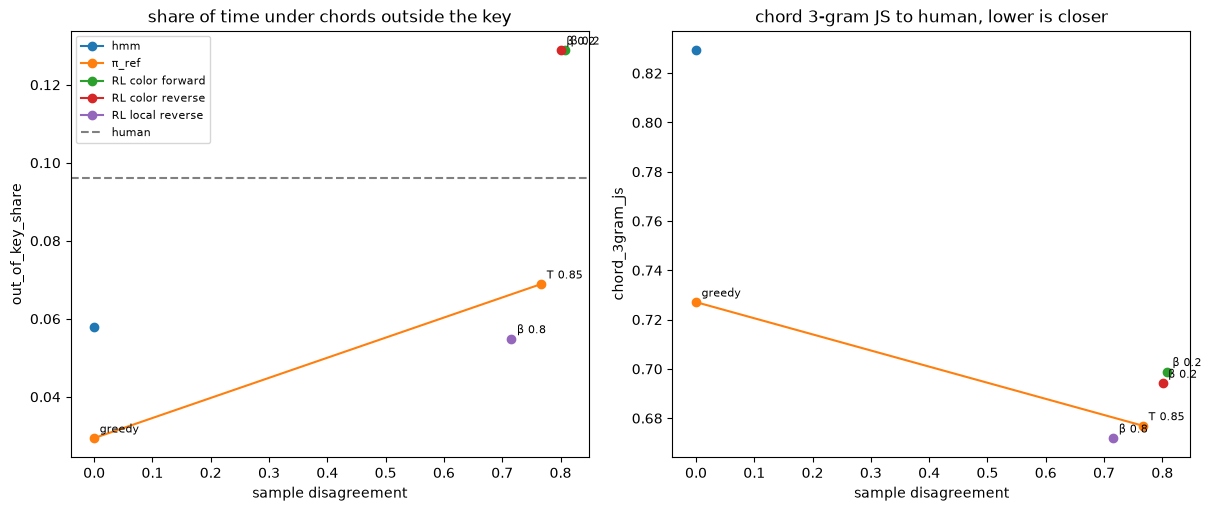

In [5]:
def family(row: dict) -> tuple[str, str | None, float]:
	"""Line a system belongs to, the label of its point, and its place along the line."""
	if row["divergence"] is not None:
		return f"RL {row['reward']} {row['divergence']}", f"β {row['beta']:g}", row["beta"]

	if row["kind"] == "rerank":
		if row["beta"] == 0:
			return "best-of-N", None, 0.0
		return "SIR", f"β {row['beta']:g}", row["beta"]

	if row["kind"] == "policy":
		if row["greedy"]:
			return "π_ref", "greedy", 0.0
		return "π_ref", f"T {row['temperature']:g}", row["temperature"]

	return row["system"], None, 0.0


points = results.filter(pl.col("system") != "human")
line, label, order = zip(*(family(r) for r in points.iter_rows(named=True)), strict=True)
points = points.with_columns(
	line=pl.Series(line),
	label=pl.Series(label, dtype=pl.String),
	order=pl.Series(order),
	diversity=pl.col("sample_disagreement").fill_null(0.0),
).sort("order")

panels = [
	("out_of_key_share", "share of time under chords outside the key"),
	("chord_3gram_js", "chord 3-gram JS to human, lower is closer"),
]

fig, axes = plt.subplots(1, len(panels), figsize=(12, 5), layout="constrained")
for ax, (column, title) in zip(axes, panels, strict=True):
	if column not in points:
		ax.set_visible(False)
		continue

	for (name,), group in points.group_by("line", maintain_order=True):
		ax.plot(group["diversity"], group[column], marker="o", label=name)
		for r in group.filter(pl.col("label").is_not_null()).iter_rows(named=True):
			ax.annotate(
				r["label"],
				(r["diversity"], r[column]),
				xytext=(4, 4),
				textcoords="offset points",
				fontsize=8,
			)

	if column == "out_of_key_share" and not human.is_empty():
		ax.axhline(human[column].item(), color="gray", linestyle="--", label="human")

	ax.set(xlabel="sample disagreement", ylabel=column, title=title)

axes[0].legend(fontsize=8)
plt.show()


## Listening

Preference rankings of whole VALID songs, blind, 1 group per song: `round-1` and `round-2` hold 1 harmonization per system, `round-3` 3 draws of 1 system per group ranked among themselves, and `round-3-final` the draw ranked 1st of each system.

Every item gets a verdict, `ok` or `problem` with the bars at fault; a problem is severe when it marks 3 bars or more, or the whole song.

Ranks in `round-3` compare draws of 1 system, not systems.


In [6]:
SEVERE_BARS = 3
ROUNDS = ["round-1", "round-2", "round-3", "round-3-final"]


def system_name(policy: dict) -> str:
	"""Short name of a system from the model it samples and its temperature."""
	model = Path(policy["model"])
	if model.parts[:2] == ("runs", "rl"):
		return model.parent.name
	return f"π_ref T {policy['temperature']:g}"


def judged(name: str) -> list[dict]:
	"""! row per judged item of the round `name` outside its repeats, with its system."""
	directory = LISTENING_DIR / name
	key = json.loads((directory / "key.json").read_text())
	systems = [system_name(p) for p in key["policies"]]
	drawn = key.get("draws", 1) > 1
	rows = []

	with (directory / "results.csv").open(encoding="utf-8", newline="") as f:
		for r in csv.DictReader(f):
			if r["group_id"].startswith("r"):
				continue

			song = key["songs"][r["group_id"]]
			index = song["policy"] if drawn else "abcdefgh".index(r["item_id"])
			marked = len(r["problem_bars"].split(";")) if r["problem_bars"] else 0
			rows.append(
				{
					"round": name,
					"system": systems[index],
					"first_draw": not drawn or r["item_id"] == "a",
					"rank": int(r["rank"]),
					"verdict": r["verdict"],
					"severe": r["verdict"] == "problem" and (marked == 0 or marked >= SEVERE_BARS),
					"marked_bars": marked / song["bars"],
				}
			)

	return rows
	

listening = pl.from_dicts([row for name in ROUNDS for row in judged(name)])
listening.group_by("round", "system", maintain_order=True).agg(
	items=pl.len(),
	ok=(pl.col("verdict") == "ok").sum(),
	first_draw_ok=((pl.col("verdict") == "ok") & pl.col("first_draw")).sum(),
	severe=pl.col("severe").sum(),
	mean_rank=pl.col("rank").mean(),
	marked_bars=pl.col("marked_bars").mean(),
).sort("round", "system")


round,system,items,ok,first_draw_ok,severe,mean_rank,marked_bars
str,str,u32,u32,u32,u32,f64,f64
"""round-1""","""forward-b0.2""",20,14,14,1,1.950,0.039
"""round-1""","""reverse-b0.2""",20,14,14,2,1.750,0.087
"""round-1""","""π_ref T 0.85""",20,11,11,3,2.200,0.068
"""round-2""","""local-b0.8""",20,16,16,1,1.800,0.049
"""round-2""","""reverse-b0.2""",20,10,10,2,2.200,0.163
"""round-2""","""π_ref T 0.85""",20,15,15,0,2.000,0.036
"""round-3""","""forward-b0.2""",30,16,4,8,2.000,0.189
"""round-3""","""local-b0.8""",30,19,6,4,2.033,0.069
"""round-3""","""reverse-b0.2""",30,16,7,5,2.067,0.192
